# Predicting Precipitation Near Irvine

AI SCI 290A

I start by plotting precipitation and looking at the values. Then I try two questions: will tomorrow's value be above zero, and how large will it be?

I try recent averages, other weather variables, nearby points, predicting the change, and a small neural network. I also try predicting two and three days ahead.

I use the `tp` values saved in the files. I still need to confirm how the daily averages were made, so I cannot call them daily rainfall totals.

## 1. Find and load the precipitation files

In [1]:
import glob
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

DATA_DIR = "C:/Users/giorg/Desktop/290A/Project1_WeatherPrediction/data/data"
precip_files = sorted(glob.glob(f"{DATA_DIR}/**/total_precipitation*.nc", recursive=True))

print("Precipitation files:", len(precip_files))
print("First file:", precip_files[0])

Precipitation files: 12
First file: C:/Users/giorg/Desktop/290A/Project1_WeatherPrediction/data/data\2009_JanFeb\total_precipitation_0_daily-mean.nc


In [2]:
ds_precip = xr.open_mfdataset(precip_files, combine="by_coords")
ds_precip

<xarray.Dataset> Size: 73MB
Dimensions:     (valid_time: 730, latitude: 105, longitude: 237)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
    number      int64 8B 0
Data variables:
    tp          (valid_time, latitude, longitude) float32 73MB dask.array<chunksize=(59, 105, 237), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-12-20T19:43 GRIB to CDM+CF via cfgrib-0.9.1...

## 2. Check what tp means

`tp` stands for total precipitation. I check the units and file notes to understand what the daily values mean.

In [3]:
print("Variable name:", ds_precip["tp"].attrs.get("long_name"))
print("Units:", ds_precip["tp"].attrs.get("units"))
print("Step type:", ds_precip["tp"].attrs.get("GRIB_stepType"))
print("First date:", ds_precip["valid_time"].values[0])
print("Last date:", ds_precip["valid_time"].values[-1])

Variable name: Total precipitation
Units: m
Step type: accum
First date: 2009-01-01T00:00:00.000000000
Last date: 2010-12-31T00:00:00.000000000


In [4]:
ds_precip["tp"].attrs

{'GRIB_paramId': np.int64(228),
 'GRIB_dataType': 'fc',
 'GRIB_numberOfPoints': np.int64(24885),
 'GRIB_typeOfLevel': 'surface',
 'GRIB_stepUnits': np.int64(1),
 'GRIB_stepType': 'accum',
 'GRIB_gridType': 'regular_ll',
 'GRIB_uvRelativeToGrid': np.int64(0),
 'GRIB_NV': np.int64(0),
 'GRIB_Nx': np.int64(237),
 'GRIB_Ny': np.int64(105),
 'GRIB_cfName': 'unknown',
 'GRIB_cfVarName': 'tp',
 'GRIB_gridDefinitionDescription': 'Latitude/Longitude Grid',
 'GRIB_iDirectionIncrementInDegrees': np.float64(0.25),
 'GRIB_iScansNegatively': np.int64(0),
 'GRIB_jDirectionIncrementInDegrees': np.float64(0.25),
 'GRIB_jPointsAreConsecutive': np.int64(0),
 'GRIB_jScansPositively': np.int64(0),
 'GRIB_latitudeOfFirstGridPointInDegrees': np.float64(50.0),
 'GRIB_latitudeOfLastGridPointInDegrees': np.float64(24.0),
 'GRIB_longitudeOfFirstGridPointInDegrees': np.float64(-125.0),
 'GRIB_longitudeOfLastGridPointInDegrees': np.float64(-66.0),
 'GRIB_missingValue': np.float64(3.4028234663852886e+38),
 'GRIB_na

In [5]:
# Look at one source file so I can read its processing history.
first_precip_file = xr.open_dataset(precip_files[0])
print(first_precip_file.attrs.get("history", "No history found"))
first_precip_file.close()

2025-12-20T19:43 GRIB to CDM+CF via cfgrib-0.9.15.1/ecCodes-2.42.0 with {"source": "total_precipitation.grib", "filter_by_keys": {"stream": ["oper"]}, "encode_cf": ["parameter", "time", "geography", "vertical"]}
earthkit.transforms.aggregate.temporal.daily_reduce(total_precipitation_0, how=mean, **{'time_shift': {'hours': -1}})


### What I still need to confirm

The file notes say `how=mean`, and the unit is meters. I still do not know which hours were used. I keep the original values and do not call them daily totals or mm/day.

## 3. Select the point near Irvine

I use the same grid point as in the temperature and wind notebooks.

In [6]:
precip_irvine = ds_precip["tp"].sel(
    latitude=33.75, longitude=-117.75, method="nearest"
)

print("Latitude:", float(precip_irvine.latitude))
print("Longitude:", float(precip_irvine.longitude))
precip_series = precip_irvine.to_series()
precip_series.head()

Latitude: 33.75
Longitude: -117.75


valid_time
2009-01-01    3.973643e-08
2009-01-02    1.390775e-07
2009-01-03    1.529852e-05
2009-01-04    1.547734e-05
2009-01-05    0.000000e+00
Name: tp, dtype: float32

In [7]:
print("Dates sorted:", precip_series.index.is_monotonic_increasing)
print("Dates unique:", precip_series.index.is_unique)
print("Missing values:", precip_series.isna().sum())
expected_dates = pd.date_range(precip_series.index.min(), precip_series.index.max(), freq="D")
print("Missing dates:", expected_dates.difference(precip_series.index))

Dates sorted: True
Dates unique: True
Missing values: 0
Missing dates: DatetimeIndex([], dtype='datetime64[ns]', freq='D')


## 4. Look at January 2009-June 2010

I plot this period to see how large the values are and how often they are zero. I leave July-December 2010 out of these plots.

In [8]:
precip_dev = precip_series.loc["2009-01-01":"2010-06-30"]
print("Development days:", len(precip_dev))
print("Exactly zero:", (precip_dev == 0).sum())
print("Positive values:", (precip_dev > 0).sum())
print("Negative values:", (precip_dev < 0).sum())
precip_dev.describe()

Development days: 546
Exactly zero: 317
Positive values: 229
Negative values: 0


count    5.460000e+02
mean     4.380208e-05
std      2.022330e-04
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      8.742015e-07
max      2.204378e-03
Name: tp, dtype: float64

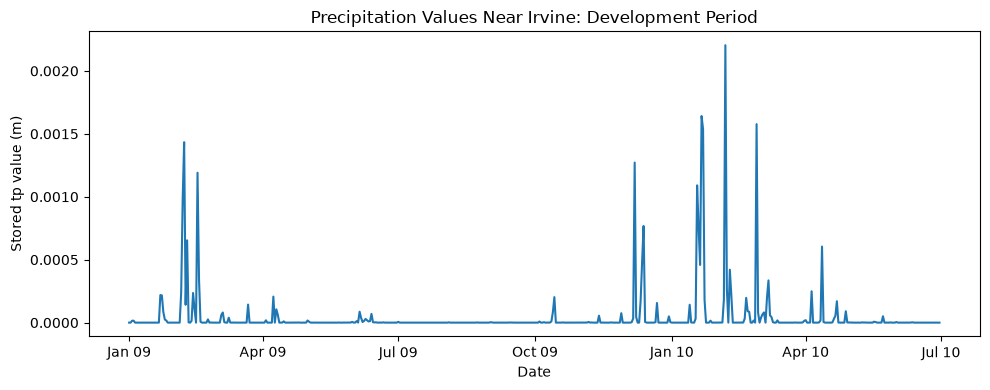

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(precip_dev.index, precip_dev)
ax.set_xlabel("Date")
ax.set_ylabel("Stored tp value (m)")
ax.set_title("Precipitation Values Near Irvine: Development Period")

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
fig.tight_layout()

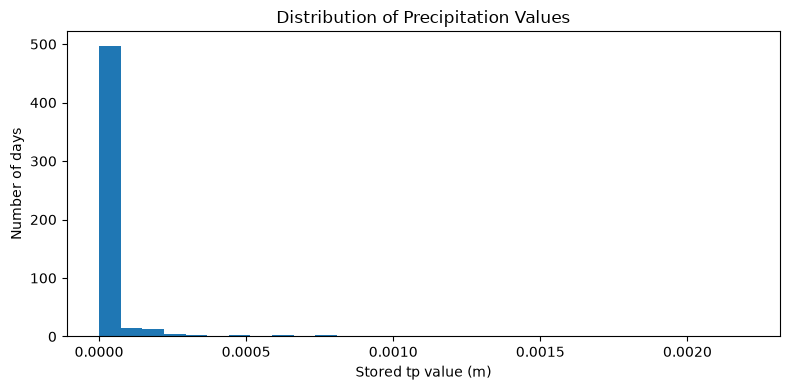

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(precip_dev.dropna(), bins=30)
ax.set_xlabel("Stored tp value (m)")
ax.set_ylabel("Number of days")
ax.set_title("Distribution of Precipitation Values")
fig.tight_layout()

### First observations

There are 546 days: 317 zeros and 229 positive values, with no negative or missing values. The dates are sorted with no duplicates or gaps. Some positive values are very small.

### A precipitation map and recent averages

I plot January 21, 2009 and mark the Irvine point with a dot. I also plot the daily values and their 3-day and 7-day averages.

I change meters to mm to make the numbers easier to read. The averages use today and earlier days. The unit change does not turn the file's values into daily rainfall totals.

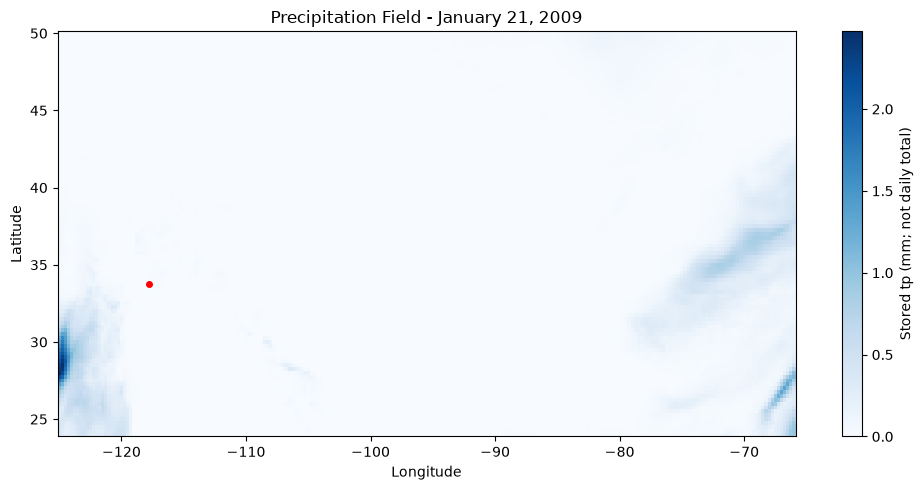

In [11]:
tp_day = (ds_precip["tp"].sel(valid_time="2009-01-21") * 1000).compute(scheduler="single-threaded")
fig, ax = plt.subplots(figsize=(10, 5))
tp_day.plot(ax=ax, cmap="Blues", cbar_kwargs={"label": "Stored tp (mm; not daily total)"})
ax.plot(-117.75, 33.75, "ro", markersize=4)
ax.set_title("Precipitation Field - January 21, 2009")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
fig.tight_layout()

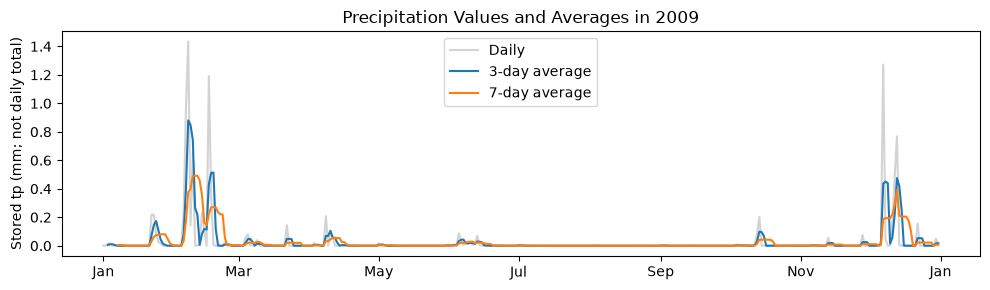

In [12]:
tp_plot = pd.DataFrame({"tp": precip_series.loc["2009"].astype(float) * 1000})
tp_plot["tp_3day"] = tp_plot["tp"].rolling(3).mean()
tp_plot["tp_7day"] = tp_plot["tp"].rolling(7).mean()
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(tp_plot.index, tp_plot["tp"], color="lightgray", label="Daily")
ax.plot(tp_plot.index, tp_plot["tp_3day"], label="3-day average")
ax.plot(tp_plot.index, tp_plot["tp_7day"], label="7-day average")
ax.set_ylabel("Stored tp (mm; not daily total)")
ax.set_title("Precipitation Values and Averages in 2009")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend()
fig.tight_layout()

## 5. Start with positive or zero

My first question is whether tomorrow's `tp` will be above zero. I use 1 for `tp > 0` and 0 for `tp == 0`. Even a very small value counts as 1. Since I do not know which hours went into the daily values, 0 may not mean it was dry all day.

I compare always predicting zero, copying today's answer, and logistic regression. The model uses today's tp, temperature, pressure, u, and v after today's data are available.

I use the same three validation rounds: Jan-Feb, Mar-Apr, and May-Jun 2010. The July-December comparison comes later in notebook 06.

## 6. Check how the daily values were made

All 12 files say `how=mean` and show a -1 hour shift. They do not say which hours were used. The [ECMWF notes](https://confluence.ecmwf.int/spaces/CKB/pages/462888259/ERA5%2Bfamily%2Bpost-processed%2Bdaily%2Bstatistics%2Bdocumentation) say the service can use data every 1, 3, or 6 hours. The shift does not answer that question.

If a value is the average of all 24 one-hour rainfall amounts, I could multiply it by 24 and then by 1000 to get a daily total in mm. I have not confirmed that this is how these files were made, so I do not use that conversion.

For now, I work with the saved values. I first predict positive or zero, then try predicting the number itself. In the numerical part, I only change meters to mm.

## 7. Put today’s weather in one table

I put today's weather into one table at the same Irvine grid point. Pandas matches the dates.

In [13]:
temp_files = sorted(glob.glob(f"{DATA_DIR}/**/2m_temperature*.nc", recursive=True))
ds_temp = xr.open_mfdataset(temp_files, combine="by_coords")
temp_series = (ds_temp["t2m"].sel(
    latitude=33.75, longitude=-117.75, method="nearest"
) - 273.15).to_series()
print("Same dates for temp:", temp_series.index.equals(precip_series.index))

Same dates for temp: True


In [14]:
pressure_files = sorted(glob.glob(f"{DATA_DIR}/**/mean_sea_level_pressure*.nc", recursive=True))
ds_pressure = xr.open_mfdataset(pressure_files, combine="by_coords")
pressure_series = (ds_pressure["msl"].sel(
    latitude=33.75, longitude=-117.75, method="nearest"
) / 100).to_series()
print("Same dates for pressure:", pressure_series.index.equals(precip_series.index))

Same dates for pressure: True


In [15]:
u_files = sorted(glob.glob(f"{DATA_DIR}/**/10m_u_component_of_wind*.nc", recursive=True))
ds_u = xr.open_mfdataset(u_files, combine="by_coords")
u_series = (ds_u["u10"].sel(
    latitude=33.75, longitude=-117.75, method="nearest"
)).to_series()
print("Same dates for u:", u_series.index.equals(precip_series.index))

Same dates for u: True


In [16]:
v_files = sorted(glob.glob(f"{DATA_DIR}/**/10m_v_component_of_wind*.nc", recursive=True))
ds_v = xr.open_mfdataset(v_files, combine="by_coords")
v_series = (ds_v["v10"].sel(
    latitude=33.75, longitude=-117.75, method="nearest"
)).to_series()
print("Same dates for v:", v_series.index.equals(precip_series.index))

Same dates for v: True


In [17]:
df_signal = pd.DataFrame({
    "today_tp": precip_series,
    "today_temp": temp_series,
    "pressure_hpa": pressure_series,
    "today_u": u_series,
    "today_v": v_series
})
print("Missing values:")
print(df_signal.isna().sum())
df_signal.head()

Missing values:
today_tp        0
today_temp      0
pressure_hpa    0
today_u         0
today_v         0
dtype: int64


,today_tp,today_temp,pressure_hpa,today_u,today_v
valid_time,,,,,
2009-01-01,3.973643e-08,10.976807,1017.050415,-0.581250,0.012833
2009-01-02,1.390775e-07,10.043762,1014.690857,-0.532312,0.843110
2009-01-03,1.529852e-05,10.752289,1013.045654,-0.766132,1.317292
2009-01-04,1.547734e-05,10.557648,1014.790527,-0.897218,-0.563737
2009-01-05,0.000000e+00,7.683075,1020.252808,-0.796495,-0.120888


## 8. Add tomorrow's answer

I use `shift(-1)` to put tomorrow's tp beside today's inputs. I remove rows with missing values before making the 1/0 answers. Otherwise, the missing last day could accidentally be counted as zero.

In [18]:
df_signal["tomorrow_tp"] = df_signal["today_tp"].shift(-1)
df_signal["target_date"] = df_signal.index + pd.Timedelta(days=1)
signal_features = ["today_tp", "today_temp", "pressure_hpa", "today_u", "today_v"]
df_signal_model = df_signal.dropna(subset=signal_features + ["tomorrow_tp"]).copy()
df_signal_model["today_signal"] = (df_signal_model["today_tp"] > 0).astype(int)
df_signal_model["tomorrow_signal"] = (df_signal_model["tomorrow_tp"] > 0).astype(int)

print("Modeling rows:", len(df_signal_model))
df_signal_model[["today_tp", "tomorrow_tp", "today_signal", "tomorrow_signal", "target_date"]].head()

Modeling rows: 729


,today_tp,tomorrow_tp,today_signal,tomorrow_signal,target_date
valid_time,,,,,
2009-01-01,3.973643e-08,1.390775e-07,1,1,2009-01-02
2009-01-02,1.390775e-07,1.529852e-05,1,1,2009-01-03
2009-01-03,1.529852e-05,1.547734e-05,1,1,2009-01-04
2009-01-04,1.547734e-05,0.000000e+00,1,0,2009-01-05
2009-01-05,0.000000e+00,0.000000e+00,0,0,2009-01-06


## 9. Round 1: January-February 2010

I train using days being predicted in 2009, then check January-February 2010. I also count how many validation days are zero or positive.

In [19]:
train_signal_1 = df_signal_model[df_signal_model["target_date"] < "2010-01-01"].copy()
val_signal_1 = df_signal_model[
    (df_signal_model["target_date"] >= "2010-01-01") &
    (df_signal_model["target_date"] < "2010-03-01")
].copy()
print("Training rows:", len(train_signal_1))
print("Validation rows:", len(val_signal_1))
print("Training labels:")
print(train_signal_1["tomorrow_signal"].value_counts().sort_index())
print("Validation labels:")
print(val_signal_1["tomorrow_signal"].value_counts().sort_index())

Training rows: 364
Validation rows: 59
Training labels:
tomorrow_signal
0    220
1    144
Name: count, dtype: int64
Validation labels:
tomorrow_signal
0    30
1    29
Name: count, dtype: int64


### Two simple guesses

The first always predicts zero. Persistence predicts that tomorrow's label is the same as today's.

In [20]:
val_signal_1["always_zero"] = 0
val_signal_1["persistence"] = val_signal_1["today_signal"]

### Scale the inputs and train logistic regression

Temperature, pressure, wind, and precipitation use very different number ranges. I use `StandardScaler` to put them on a similar scale. It learns the averages and spread from training data, and I use those same values to scale validation data.

I use the default logistic regression settings. A predicted probability of at least 0.5 counts as 1.

In [21]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

scaler_signal_1 = StandardScaler()
X_train_signal_1 = scaler_signal_1.fit_transform(train_signal_1[signal_features])
X_val_signal_1 = scaler_signal_1.transform(val_signal_1[signal_features])

logistic_signal_1 = LogisticRegression(max_iter=1000)
logistic_signal_1.fit(X_train_signal_1, train_signal_1["tomorrow_signal"])

val_signal_1["signal_probability"] = logistic_signal_1.predict_proba(X_val_signal_1)[:, 1]
val_signal_1["logistic"] = (val_signal_1["signal_probability"] >= 0.5).astype(int)
val_signal_1[["target_date", "tomorrow_signal", "signal_probability", "logistic"]].head()

,target_date,tomorrow_signal,signal_probability,logistic
valid_time,,,,
2009-12-31,2010-01-01,0,0.325264,0
2010-01-01,2010-01-02,0,0.189306,0
2010-01-02,2010-01-03,0,0.167444,0
2010-01-03,2010-01-04,0,0.149491,0
2010-01-04,2010-01-05,0,0.130140,0


## 10. Compare the first-round results

Accuracy is the fraction of correct predictions. Precision tells me how often a predicted positive is right; recall tells me how many real positives I find.

Always-zero has no positive predictions, so its precision is undefined. These first tables display it as 0.

In [22]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

y_val_signal_1 = val_signal_1["tomorrow_signal"]

In [23]:
always_zero_scores_1 = {
    "Model": "Always zero",
    "Accuracy": accuracy_score(y_val_signal_1, val_signal_1["always_zero"]),
    "Precision": precision_score(y_val_signal_1, val_signal_1["always_zero"], zero_division=0),
    "Recall": recall_score(y_val_signal_1, val_signal_1["always_zero"], zero_division=0),
}

In [24]:
persistence_scores_1 = {
    "Model": "Persistence",
    "Accuracy": accuracy_score(y_val_signal_1, val_signal_1["persistence"]),
    "Precision": precision_score(y_val_signal_1, val_signal_1["persistence"], zero_division=0),
    "Recall": recall_score(y_val_signal_1, val_signal_1["persistence"], zero_division=0),
}

In [25]:
logistic_scores_1 = {
    "Model": "Logistic",
    "Accuracy": accuracy_score(y_val_signal_1, val_signal_1["logistic"]),
    "Precision": precision_score(y_val_signal_1, val_signal_1["logistic"], zero_division=0),
    "Recall": recall_score(y_val_signal_1, val_signal_1["logistic"], zero_division=0),
}

In [26]:
signal_results_1 = pd.DataFrame([always_zero_scores_1, persistence_scores_1, logistic_scores_1])
signal_results_1.round(4)

,Model,Accuracy,Precision,Recall
0,Always zero,0.5085,0.0000,0.0000
1,Persistence,0.7288,0.7241,0.7241
2,Logistic,0.7288,0.8095,0.5862


In [27]:
logistic_confusion_1 = pd.DataFrame(
    confusion_matrix(y_val_signal_1, val_signal_1["logistic"], labels=[0, 1]),
    index=["Actual zero", "Actual positive"],
    columns=["Predicted zero", "Predicted positive"]
)
logistic_confusion_1

,Predicted zero,Predicted positive
Actual zero,26,4
Actual positive,12,17


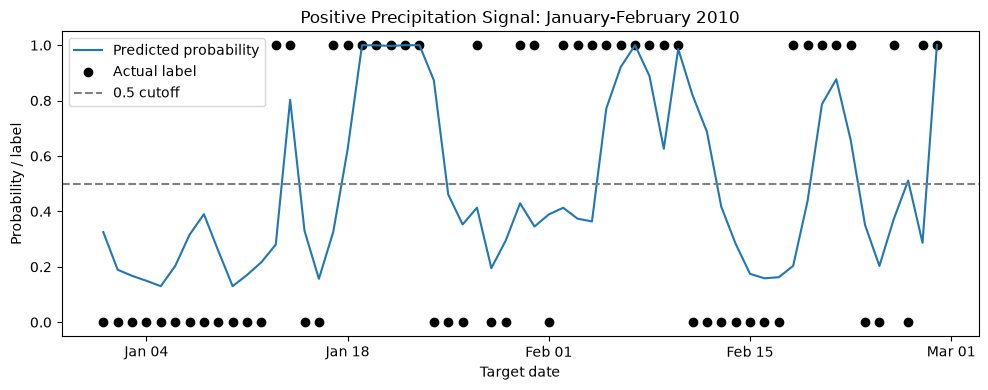

In [28]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(val_signal_1["target_date"], val_signal_1["signal_probability"], label="Predicted probability")
ax.scatter(val_signal_1["target_date"], val_signal_1["tomorrow_signal"], color="black", label="Actual label")
ax.axhline(0.5, color="gray", linestyle="--", label="0.5 cutoff")
ax.set_xlabel("Target date")
ax.set_ylabel("Probability / label")
ax.set_title("Positive Precipitation Signal: January-February 2010")
ax.legend()

ax.xaxis.set_major_locator(mdates.DayLocator(interval=14))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
fig.tight_layout()

## 11. What I found in round 1

There are 29 positive days and 30 zero days. Persistence and logistic regression both get 72.9% correct. When logistic regression predicts positive, it is right more often, but it also misses more positive days. Its recall is lower.

It finds 17 positive days and misses 12, so it is not clearly better. I keep the same settings for the next rounds.

## 12. Round 2: March-April 2010

I add the earlier months to training and train the scaler and model again. Then I check March-April. The weather inputs and the 0.5 probability cutoff stay the same.

In [29]:
train_signal_2 = df_signal_model[df_signal_model["target_date"] < "2010-03-01"].copy()
val_signal_2 = df_signal_model[
    (df_signal_model["target_date"] >= "2010-03-01") &
    (df_signal_model["target_date"] < "2010-05-01")
].copy()
print("Training rows:", len(train_signal_2))
print("Validation rows:", len(val_signal_2))
print("Training labels:")
print(train_signal_2["tomorrow_signal"].value_counts().sort_index())
print("Validation labels:")
print(val_signal_2["tomorrow_signal"].value_counts().sort_index())

Training rows: 423
Validation rows: 61
Training labels:
tomorrow_signal
0    250
1    173
Name: count, dtype: int64
Validation labels:
tomorrow_signal
0    30
1    31
Name: count, dtype: int64


In [30]:
val_signal_2["always_zero"] = 0
val_signal_2["persistence"] = val_signal_2["today_signal"]

In [31]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

scaler_signal_2 = StandardScaler()
X_train_signal_2 = scaler_signal_2.fit_transform(train_signal_2[signal_features])
X_val_signal_2 = scaler_signal_2.transform(val_signal_2[signal_features])

logistic_signal_2 = LogisticRegression(max_iter=1000)
logistic_signal_2.fit(X_train_signal_2, train_signal_2["tomorrow_signal"])

val_signal_2["signal_probability"] = logistic_signal_2.predict_proba(X_val_signal_2)[:, 1]
val_signal_2["logistic"] = (val_signal_2["signal_probability"] >= 0.5).astype(int)
val_signal_2[["target_date", "tomorrow_signal", "signal_probability", "logistic"]].head()

,target_date,tomorrow_signal,signal_probability,logistic
valid_time,,,,
2010-02-28,2010-03-01,0,0.726240,1
2010-03-01,2010-03-02,1,0.461777,0
2010-03-02,2010-03-03,1,0.520265,1
2010-03-03,2010-03-04,1,0.543746,1
2010-03-04,2010-03-05,0,0.551556,1


In [32]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

y_val_signal_2 = val_signal_2["tomorrow_signal"]

In [33]:
always_zero_scores_2 = {
    "Model": "Always zero",
    "Accuracy": accuracy_score(y_val_signal_2, val_signal_2["always_zero"]),
    "Precision": precision_score(y_val_signal_2, val_signal_2["always_zero"], zero_division=0),
    "Recall": recall_score(y_val_signal_2, val_signal_2["always_zero"], zero_division=0),
}

In [34]:
persistence_scores_2 = {
    "Model": "Persistence",
    "Accuracy": accuracy_score(y_val_signal_2, val_signal_2["persistence"]),
    "Precision": precision_score(y_val_signal_2, val_signal_2["persistence"], zero_division=0),
    "Recall": recall_score(y_val_signal_2, val_signal_2["persistence"], zero_division=0),
}

In [35]:
logistic_scores_2 = {
    "Model": "Logistic",
    "Accuracy": accuracy_score(y_val_signal_2, val_signal_2["logistic"]),
    "Precision": precision_score(y_val_signal_2, val_signal_2["logistic"], zero_division=0),
    "Recall": recall_score(y_val_signal_2, val_signal_2["logistic"], zero_division=0),
}

In [36]:
signal_results_2 = pd.DataFrame([always_zero_scores_2, persistence_scores_2, logistic_scores_2])
signal_results_2.round(4)

,Model,Accuracy,Precision,Recall
0,Always zero,0.4918,0.0000,0.0000
1,Persistence,0.6066,0.6129,0.6129
2,Logistic,0.6393,0.6364,0.6774


In [37]:
logistic_confusion_2 = pd.DataFrame(
    confusion_matrix(y_val_signal_2, val_signal_2["logistic"], labels=[0, 1]),
    index=["Actual zero", "Actual positive"],
    columns=["Predicted zero", "Predicted positive"]
)
logistic_confusion_2

,Predicted zero,Predicted positive
Actual zero,18,12
Actual positive,10,21


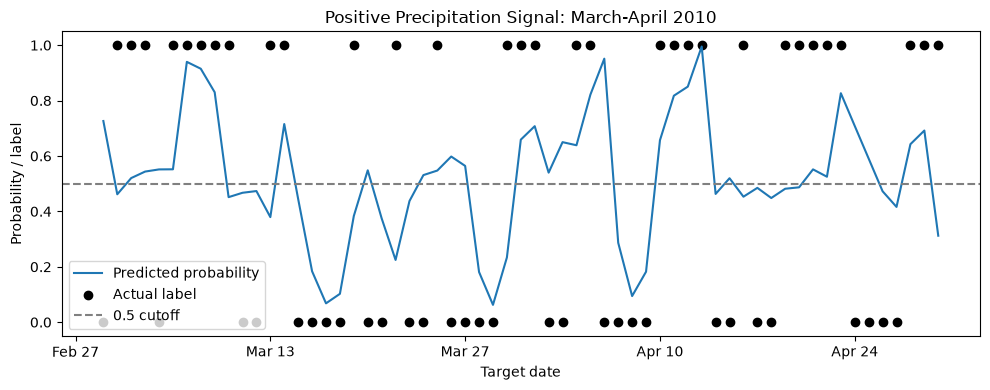

In [38]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(val_signal_2["target_date"], val_signal_2["signal_probability"], label="Predicted probability")
ax.scatter(val_signal_2["target_date"], val_signal_2["tomorrow_signal"], color="black", label="Actual label")
ax.axhline(0.5, color="gray", linestyle="--", label="0.5 cutoff")
ax.set_xlabel("Target date")
ax.set_ylabel("Probability / label")
ax.set_title("Positive Precipitation Signal: March-April 2010")
ax.legend()

ax.xaxis.set_major_locator(mdates.DayLocator(interval=14))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
fig.tight_layout()

## 13. Round 3: May-June 2010

I repeat the same steps for May-June, adding the earlier months to training.

In [39]:
train_signal_3 = df_signal_model[df_signal_model["target_date"] < "2010-05-01"].copy()
val_signal_3 = df_signal_model[
    (df_signal_model["target_date"] >= "2010-05-01") &
    (df_signal_model["target_date"] < "2010-07-01")
].copy()
print("Training rows:", len(train_signal_3))
print("Validation rows:", len(val_signal_3))
print("Training labels:")
print(train_signal_3["tomorrow_signal"].value_counts().sort_index())
print("Validation labels:")
print(val_signal_3["tomorrow_signal"].value_counts().sort_index())

Training rows: 484
Validation rows: 61
Training labels:
tomorrow_signal
0    280
1    204
Name: count, dtype: int64
Validation labels:
tomorrow_signal
0    37
1    24
Name: count, dtype: int64


In [40]:
val_signal_3["always_zero"] = 0
val_signal_3["persistence"] = val_signal_3["today_signal"]

In [41]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

scaler_signal_3 = StandardScaler()
X_train_signal_3 = scaler_signal_3.fit_transform(train_signal_3[signal_features])
X_val_signal_3 = scaler_signal_3.transform(val_signal_3[signal_features])

logistic_signal_3 = LogisticRegression(max_iter=1000)
logistic_signal_3.fit(X_train_signal_3, train_signal_3["tomorrow_signal"])

val_signal_3["signal_probability"] = logistic_signal_3.predict_proba(X_val_signal_3)[:, 1]
val_signal_3["logistic"] = (val_signal_3["signal_probability"] >= 0.5).astype(int)
val_signal_3[["target_date", "tomorrow_signal", "signal_probability", "logistic"]].head()

,target_date,tomorrow_signal,signal_probability,logistic
valid_time,,,,
2010-04-30,2010-05-01,0,0.281444,0
2010-05-01,2010-05-02,1,0.675245,1
2010-05-02,2010-05-03,0,0.837837,1
2010-05-03,2010-05-04,0,0.341955,0
2010-05-04,2010-05-05,0,0.396314,0


In [42]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

y_val_signal_3 = val_signal_3["tomorrow_signal"]

In [43]:
always_zero_scores_3 = {
    "Model": "Always zero",
    "Accuracy": accuracy_score(y_val_signal_3, val_signal_3["always_zero"]),
    "Precision": precision_score(y_val_signal_3, val_signal_3["always_zero"], zero_division=0),
    "Recall": recall_score(y_val_signal_3, val_signal_3["always_zero"], zero_division=0),
}

In [44]:
persistence_scores_3 = {
    "Model": "Persistence",
    "Accuracy": accuracy_score(y_val_signal_3, val_signal_3["persistence"]),
    "Precision": precision_score(y_val_signal_3, val_signal_3["persistence"], zero_division=0),
    "Recall": recall_score(y_val_signal_3, val_signal_3["persistence"], zero_division=0),
}

In [45]:
logistic_scores_3 = {
    "Model": "Logistic",
    "Accuracy": accuracy_score(y_val_signal_3, val_signal_3["logistic"]),
    "Precision": precision_score(y_val_signal_3, val_signal_3["logistic"], zero_division=0),
    "Recall": recall_score(y_val_signal_3, val_signal_3["logistic"], zero_division=0),
}

In [46]:
signal_results_3 = pd.DataFrame([always_zero_scores_3, persistence_scores_3, logistic_scores_3])
signal_results_3.round(4)

,Model,Accuracy,Precision,Recall
0,Always zero,0.6066,0.0000,0.0000
1,Persistence,0.6230,0.5200,0.5417
2,Logistic,0.6557,0.5405,0.8333


In [47]:
logistic_confusion_3 = pd.DataFrame(
    confusion_matrix(y_val_signal_3, val_signal_3["logistic"], labels=[0, 1]),
    index=["Actual zero", "Actual positive"],
    columns=["Predicted zero", "Predicted positive"]
)
logistic_confusion_3

,Predicted zero,Predicted positive
Actual zero,20,17
Actual positive,4,20


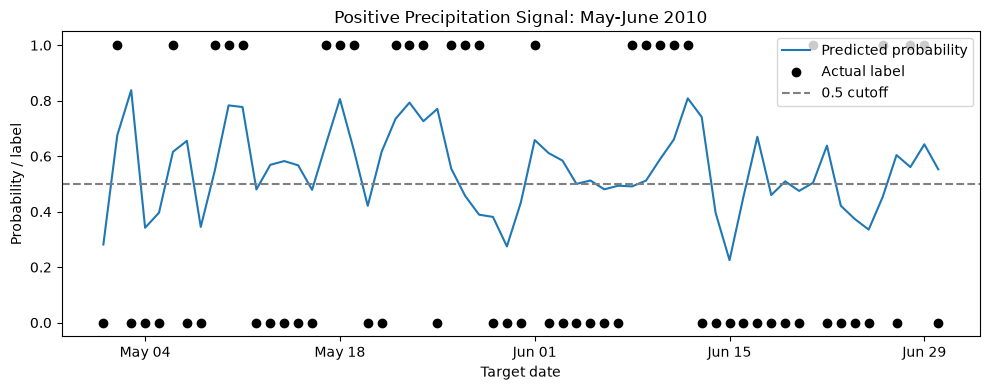

In [48]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(val_signal_3["target_date"], val_signal_3["signal_probability"], label="Predicted probability")
ax.scatter(val_signal_3["target_date"], val_signal_3["tomorrow_signal"], color="black", label="Actual label")
ax.axhline(0.5, color="gray", linestyle="--", label="0.5 cutoff")
ax.set_xlabel("Target date")
ax.set_ylabel("Probability / label")
ax.set_title("Positive Precipitation Signal: May-June 2010")
ax.legend()

ax.xaxis.set_major_locator(mdates.DayLocator(interval=14))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
fig.tight_layout()

## 14. Compare all three rounds

I put the three rounds together. All months below are in 2010.

In [49]:
signal_results_1["Period"] = "Jan-Feb"
signal_results_2["Period"] = "Mar-Apr"
signal_results_3["Period"] = "May-Jun"
signal_results = pd.concat([signal_results_1, signal_results_2, signal_results_3], ignore_index=True)
signal_results[["Period", "Model", "Accuracy", "Precision", "Recall"]].round(4)

,Period,Model,Accuracy,Precision,Recall
0,Jan-Feb,Always zero,0.5085,0.0000,0.0000
1,Jan-Feb,Persistence,0.7288,0.7241,0.7241
2,Jan-Feb,Logistic,0.7288,0.8095,0.5862
3,Mar-Apr,Always zero,0.4918,0.0000,0.0000
4,Mar-Apr,Persistence,0.6066,0.6129,0.6129
5,Mar-Apr,Logistic,0.6393,0.6364,0.6774
6,May-Jun,Always zero,0.6066,0.0000,0.0000
7,May-Jun,Persistence,0.6230,0.5200,0.5417
8,May-Jun,Logistic,0.6557,0.5405,0.8333


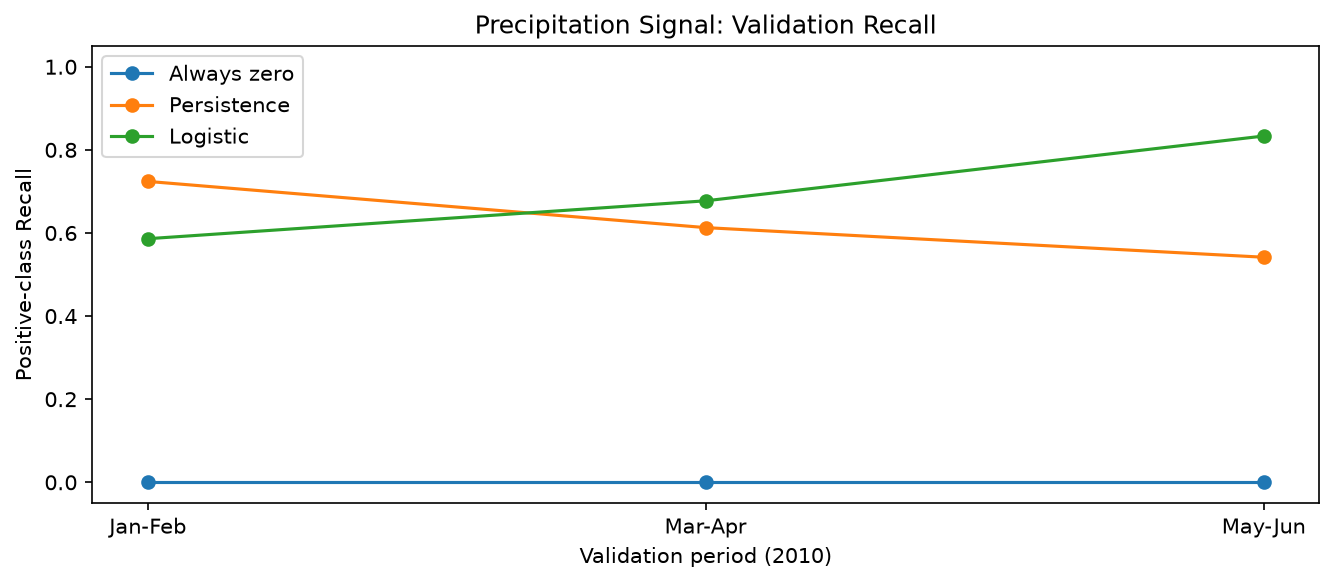

In [50]:
persistence_scores = signal_results[signal_results["Model"] == "Persistence"]
logistic_scores = signal_results[signal_results["Model"] == "Logistic"]
zero_scores = signal_results[signal_results["Model"] == "Always zero"]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(zero_scores["Period"], zero_scores["Recall"], marker="o", label="Always zero")
ax.plot(persistence_scores["Period"], persistence_scores["Recall"], marker="o", label="Persistence")
ax.plot(logistic_scores["Period"], logistic_scores["Recall"], marker="o", label="Logistic")
ax.set_xlabel("Validation period (2010)")
ax.set_ylabel("Positive-class Recall")
ax.set_ylim(-0.05, 1.05)
ax.set_title("Precipitation Signal: Validation Recall")
ax.legend()
fig.tight_layout()

### Put all validation predictions together

I collect all 181 predictions and calculate the scores for them together. I want one result for the whole validation period.

In [51]:
signal_validation_all = pd.concat([val_signal_1, val_signal_2, val_signal_3])
y_signal_all = signal_validation_all["tomorrow_signal"]
print("Validation days:", len(signal_validation_all))

Validation days: 181


In [52]:
always_zero_scores_all = {
    "Model": "Always zero",
    "Accuracy": accuracy_score(y_signal_all, signal_validation_all["always_zero"]),
    "Precision": precision_score(y_signal_all, signal_validation_all["always_zero"], zero_division=0),
    "Recall": recall_score(y_signal_all, signal_validation_all["always_zero"], zero_division=0),
}

In [53]:
persistence_scores_all = {
    "Model": "Persistence",
    "Accuracy": accuracy_score(y_signal_all, signal_validation_all["persistence"]),
    "Precision": precision_score(y_signal_all, signal_validation_all["persistence"], zero_division=0),
    "Recall": recall_score(y_signal_all, signal_validation_all["persistence"], zero_division=0),
}

In [54]:
logistic_scores_all = {
    "Model": "Logistic",
    "Accuracy": accuracy_score(y_signal_all, signal_validation_all["logistic"]),
    # How often was a positive prediction right?
    "Precision": precision_score(y_signal_all, signal_validation_all["logistic"], zero_division=0),
    # How many of the real positive days did I find?
    "Recall": recall_score(y_signal_all, signal_validation_all["logistic"], zero_division=0),
}

In [55]:
signal_summary = pd.DataFrame([always_zero_scores_all, persistence_scores_all, logistic_scores_all])
signal_summary.round(4)

,Model,Accuracy,Precision,Recall
0,Always zero,0.5359,0.0000,0.0000
1,Persistence,0.6519,0.6235,0.6310
2,Logistic,0.6740,0.6374,0.6905


## 15. What I found across the three rounds

Logistic finds about 69% of positive days, compared with 63% for persistence. Its precision is also slightly higher: 0.6374 compared with 0.6235. Always-zero gets 0.5359 accuracy but finds no positives.

Logistic has higher recall in the last two rounds, but lower recall in the first. It helps a little overall, not in every period. Next I look at monthly differences.

## 16. Look for wet and dry months in 2009

I count how many days have positive values in each month of 2009. Here I use the dates of the actual observations. Since even tiny values count as positive, I also need to look at their size before calling a month wet or dry.

In [56]:
precip_2009 = precip_series.loc["2009-01-01":"2009-12-31"]
season_table_2009 = pd.DataFrame({"stored_tp": precip_2009}).dropna()
season_table_2009["positive_signal"] = (season_table_2009["stored_tp"] > 0).astype(int)
season_table_2009["month"] = season_table_2009.index.month

print("Observed days in 2009:", len(season_table_2009))
print("Missing values in 2009:", precip_2009.isna().sum())
season_table_2009.head()

Observed days in 2009: 365
Missing values in 2009: 0


,stored_tp,positive_signal,month
valid_time,,,
2009-01-01,3.973643e-08,1,1
2009-01-02,1.390775e-07,1,1
2009-01-03,1.529852e-05,1,1
2009-01-04,1.547734e-05,1,1
2009-01-05,0.000000e+00,0,1


In [57]:
monthly_2009 = season_table_2009.groupby("month")["positive_signal"].agg(["count", "sum", "mean"])
monthly_2009.columns = ["observed_days", "positive_days", "positive_fraction"]
monthly_2009["zero_days"] = monthly_2009["observed_days"] - monthly_2009["positive_days"]
monthly_2009["positive_percent"] = monthly_2009["positive_fraction"] * 100
monthly_2009[["observed_days", "positive_days", "zero_days", "positive_percent"]].round(1)

,observed_days,positive_days,zero_days,positive_percent
month,,,,
1,31,11,20,35.5
2,28,17,11,60.7
3,31,16,15,51.6
4,30,15,15,50.0
5,31,11,20,35.5
6,30,19,11,63.3
7,31,5,26,16.1
8,31,5,26,16.1
9,30,9,21,30.0


### Compare the monthly proportions

I compare percentages because months have different numbers of days. All months here are in 2009.

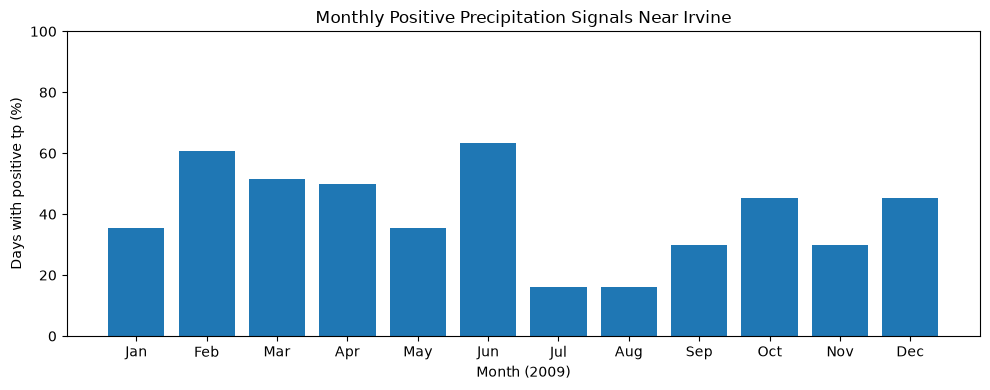

In [58]:
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(monthly_2009.index, monthly_2009["positive_percent"])
ax.set_xticks(range(1, 13), month_labels)
ax.set_ylim(0, 100)
ax.set_xlabel("Month (2009)")
ax.set_ylabel("Days with positive tp (%)")
ax.set_title("Monthly Positive Precipitation Signals Near Irvine")
fig.tight_layout()

### A simple reference for accuracy

The fraction of zero days is also the accuracy of an always-zero guess. This is just a check of the 2009 data, not validation.

In [59]:
monthly_2009["always_zero_accuracy"] = 1 - monthly_2009["positive_fraction"]
monthly_2009[["positive_days", "zero_days", "always_zero_accuracy"]].round(3)

,positive_days,zero_days,always_zero_accuracy
month,,,
1,11,20,0.645
2,17,11,0.393
3,16,15,0.484
4,15,15,0.500
5,11,20,0.645
6,19,11,0.367
7,5,26,0.839
8,5,26,0.839
9,9,21,0.700


### What I notice

July and August each have 5 positive days out of 31. Always predicting zero would get 83.9% accuracy while missing all five.

June has a higher percentage of positive days (63.3%) than February (60.7%). That surprised me, so next I check how large those values are. I do not choose a wet/dry dividing line from the counts alone. The model validation covers January-June 2010.

## 17. Are June's positive values small?

I compare positive values by month using only 2009. The median shows the middle value, while a few large values can raise the mean. I keep the original unit, meters.

In [60]:
positive_2009 = season_table_2009[season_table_2009["stored_tp"] > 0].copy()
positive_size_2009 = positive_2009.groupby("month")["stored_tp"].agg(
    ["count", "median", "mean", "max"]
)
positive_size_2009.columns = ["positive_days", "positive_median_m", "positive_mean_m", "positive_max_m"]
positive_size_2009

,positive_days,positive_median_m,positive_mean_m,positive_max_m
month,,,,
1,11,1.547734e-05,5.394220e-05,0.000219
2,17,1.051426e-04,3.153454e-04,0.001434
3,16,5.662441e-07,2.073745e-05,0.000143
4,15,4.569689e-07,2.709892e-05,0.000207
5,11,5.960464e-08,2.935077e-06,0.000017
6,19,4.688899e-06,1.599078e-05,0.000087
7,5,9.934107e-08,1.418591e-06,0.000006
8,5,1.986821e-07,7.748604e-07,0.000002
9,9,9.934107e-08,7.594073e-07,0.000003


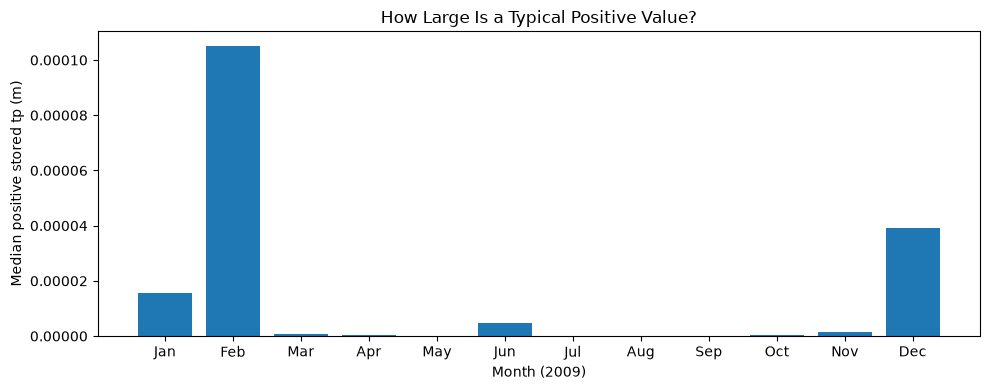

In [61]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(positive_size_2009.index, positive_size_2009["positive_median_m"])
ax.set_xticks(range(1, 13), month_labels)
ax.set_xlabel("Month (2009)")
ax.set_ylabel("Median positive stored tp (m)")
ax.set_title("How Large Is a Typical Positive Value?")
fig.tight_layout()

### Compare February and June directly

I compare the positive days in February and June on the same vertical scale. The horizontal axis is the day number within each month.

In [62]:
feb_jun_sizes = positive_size_2009.loc[[2, 6]].copy()
feb_jun_sizes.index = ["Feb 2009", "Jun 2009"]
feb_jun_sizes

,positive_days,positive_median_m,positive_mean_m,positive_max_m
Feb 2009,17,0.000105,0.000315,0.001434
Jun 2009,19,0.000005,0.000016,0.000087


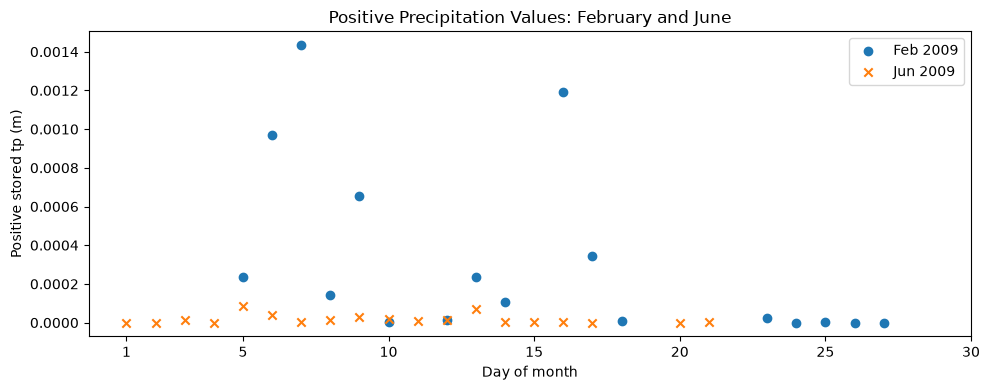

In [63]:
feb_positive = positive_2009[positive_2009["month"] == 2]["stored_tp"]
jun_positive = positive_2009[positive_2009["month"] == 6]["stored_tp"]

fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(feb_positive.index.day, feb_positive, label="Feb 2009")
ax.scatter(jun_positive.index.day, jun_positive, marker="x", label="Jun 2009")
ax.set_xlabel("Day of month")
ax.set_ylabel("Positive stored tp (m)")
ax.set_title("Positive Precipitation Values: February and June")
ax.set_xticks([1, 5, 10, 15, 20, 25, 30])
ax.legend()
fig.tight_layout()

### Also include the zero days

I also average all days, including zeros. This is the average stored value, not a monthly rainfall total.

February mean including zeros: 0.00019145969504988765
June mean including zeros: 1.0127491485611984e-05


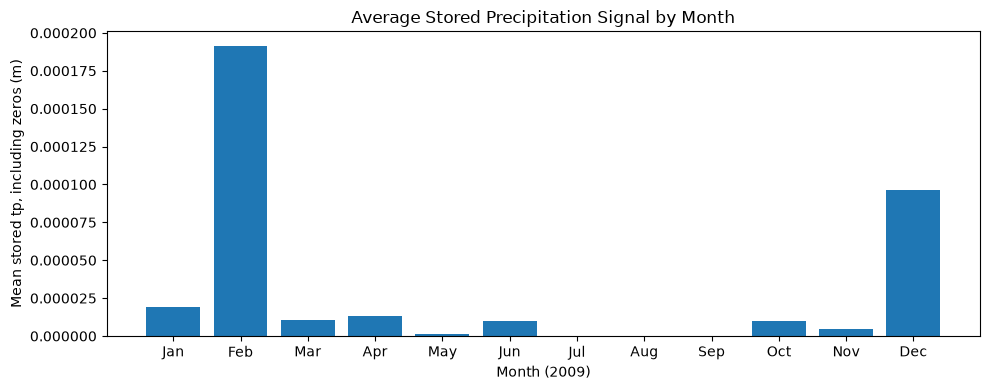

In [64]:
monthly_mean_2009 = season_table_2009.groupby("month")["stored_tp"].mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(monthly_mean_2009.index, monthly_mean_2009)
ax.set_xticks(range(1, 13), month_labels)
ax.set_xlabel("Month (2009)")
ax.set_ylabel("Mean stored tp, including zeros (m)")
ax.set_title("Average Stored Precipitation Signal by Month")
fig.tight_layout()

print("February mean including zeros:", monthly_mean_2009.loc[2])
print("June mean including zeros:", monthly_mean_2009.loc[6])

### What this comparison tells me

June has 19 positive days and February has 17, but June's values are much smaller. February's median positive value is about 22 times larger, and its mean positive value is about 20 times larger.

Counting positive days alone did not tell me which month had larger values. I keep the same positive/zero rule because I have not shown that the small values are errors. Next I look at the prediction results one month at a time.

## 18. Check results month by month

I group the predictions by the month I was trying to predict. I keep the same models and 0.5 cutoff. I also count how many actual days were positive or zero in each month.

In [65]:
monthly_predictions = signal_validation_all.copy()
monthly_predictions["target_month"] = monthly_predictions["target_date"].dt.month

monthly_targets = monthly_predictions.groupby("target_month")["tomorrow_signal"].agg(["count", "sum", "mean"])
monthly_targets.columns = ["days", "positive_days", "positive_fraction"]
monthly_targets["zero_days"] = monthly_targets["days"] - monthly_targets["positive_days"]
monthly_targets["positive_percent"] = monthly_targets["positive_fraction"] * 100
monthly_targets[["days", "positive_days", "zero_days", "positive_percent"]].round(1)

,days,positive_days,zero_days,positive_percent
target_month,,,,
1,31,12,19,38.7
2,28,17,11,60.7
3,31,15,16,48.4
4,30,16,14,53.3
5,31,14,17,45.2
6,30,10,20,33.3


### Count correct predictions and mistakes

For each month, I count:

- TP: predicted positive and it was positive.
- FP: predicted positive but it was zero, a false alarm.
- FN: predicted zero but it was positive, a missed day.
- TN: predicted zero and it was zero.

Precision = TP / (TP + FP). Of the days I called positive, how many were right?

Recall = TP / (TP + FN). Of the real positive days, how many did I find?

Here I show NaN when a score cannot be calculated. For example, always-zero has no positive predictions, so its precision cannot be calculated. The earlier tables showed 0 in that case.

In [66]:
always_zero_monthly_days = pd.DataFrame({
    "target_month": monthly_predictions["target_month"],
    "TP": ((monthly_predictions["tomorrow_signal"] == 1) & (monthly_predictions["always_zero"] == 1)).astype(int),
    "FP": ((monthly_predictions["tomorrow_signal"] == 0) & (monthly_predictions["always_zero"] == 1)).astype(int),
    "FN": ((monthly_predictions["tomorrow_signal"] == 1) & (monthly_predictions["always_zero"] == 0)).astype(int),
    "TN": ((monthly_predictions["tomorrow_signal"] == 0) & (monthly_predictions["always_zero"] == 0)).astype(int)
})
always_zero_monthly = always_zero_monthly_days.groupby("target_month").sum()
always_zero_monthly["Model"] = "Always zero"

In [67]:
persistence_monthly_days = pd.DataFrame({
    "target_month": monthly_predictions["target_month"],
    "TP": ((monthly_predictions["tomorrow_signal"] == 1) & (monthly_predictions["persistence"] == 1)).astype(int),
    "FP": ((monthly_predictions["tomorrow_signal"] == 0) & (monthly_predictions["persistence"] == 1)).astype(int),
    "FN": ((monthly_predictions["tomorrow_signal"] == 1) & (monthly_predictions["persistence"] == 0)).astype(int),
    "TN": ((monthly_predictions["tomorrow_signal"] == 0) & (monthly_predictions["persistence"] == 0)).astype(int)
})
persistence_monthly = persistence_monthly_days.groupby("target_month").sum()
persistence_monthly["Model"] = "Persistence"

In [68]:
logistic_monthly_days = pd.DataFrame({
    "target_month": monthly_predictions["target_month"],
    "TP": ((monthly_predictions["tomorrow_signal"] == 1) & (monthly_predictions["logistic"] == 1)).astype(int),
    "FP": ((monthly_predictions["tomorrow_signal"] == 0) & (monthly_predictions["logistic"] == 1)).astype(int),
    "FN": ((monthly_predictions["tomorrow_signal"] == 1) & (monthly_predictions["logistic"] == 0)).astype(int),
    "TN": ((monthly_predictions["tomorrow_signal"] == 0) & (monthly_predictions["logistic"] == 0)).astype(int)
})
logistic_monthly = logistic_monthly_days.groupby("target_month").sum()
logistic_monthly["Model"] = "Logistic"

In [69]:
monthly_scores = pd.concat([always_zero_monthly, persistence_monthly, logistic_monthly]).reset_index()
monthly_scores["days"] = monthly_scores["TP"] + monthly_scores["FP"] + monthly_scores["FN"] + monthly_scores["TN"]
monthly_scores["positive_days"] = monthly_scores["TP"] + monthly_scores["FN"]
monthly_scores["Accuracy"] = (monthly_scores["TP"] + monthly_scores["TN"]) / monthly_scores["days"]
monthly_scores["Precision"] = monthly_scores["TP"] / (monthly_scores["TP"] + monthly_scores["FP"]).replace(0, float("nan"))
monthly_scores["Recall"] = monthly_scores["TP"] / monthly_scores["positive_days"].replace(0, float("nan"))
monthly_scores = monthly_scores.sort_values(["target_month", "Model"])
monthly_scores[["target_month", "Model", "days", "positive_days", "Accuracy", "Precision", "Recall"]].round(3)

,target_month,Model,days,positive_days,Accuracy,Precision,Recall
0,1,Always zero,31,12,0.613,NaN,0.000
12,1,Logistic,31,12,0.806,0.875,0.583
6,1,Persistence,31,12,0.742,0.667,0.667
1,2,Always zero,28,17,0.393,NaN,0.000
13,2,Logistic,28,17,0.643,0.769,0.588
7,2,Persistence,28,17,0.714,0.765,0.765
2,3,Always zero,31,15,0.516,NaN,0.000
14,3,Logistic,31,15,0.613,0.600,0.600
8,3,Persistence,31,15,0.548,0.533,0.533
3,4,Always zero,30,16,0.467,NaN,0.000


### Compare the monthly pattern

I compare monthly precision and recall alongside the positive-day counts. Each month only has 28-31 days, so I should be careful about reading too much into small differences.

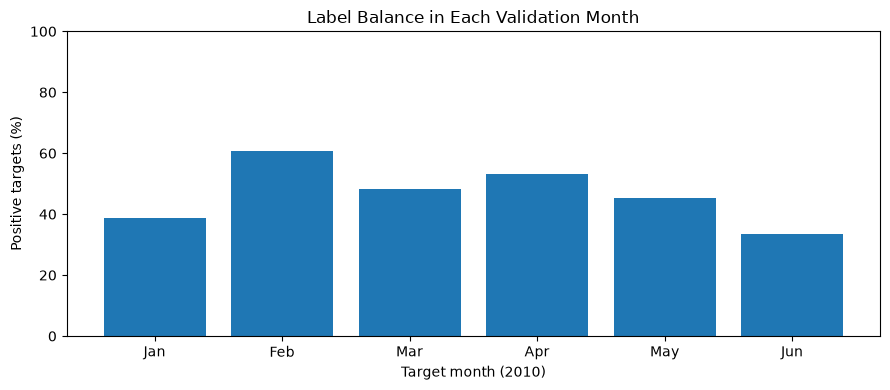

In [70]:
validation_month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(monthly_targets.index, monthly_targets["positive_percent"])
ax.set_xticks(range(1, 7), validation_month_labels)
ax.set_ylim(0, 100)
ax.set_xlabel("Target month (2010)")
ax.set_ylabel("Positive targets (%)")
ax.set_title("Label Balance in Each Validation Month")
fig.tight_layout()

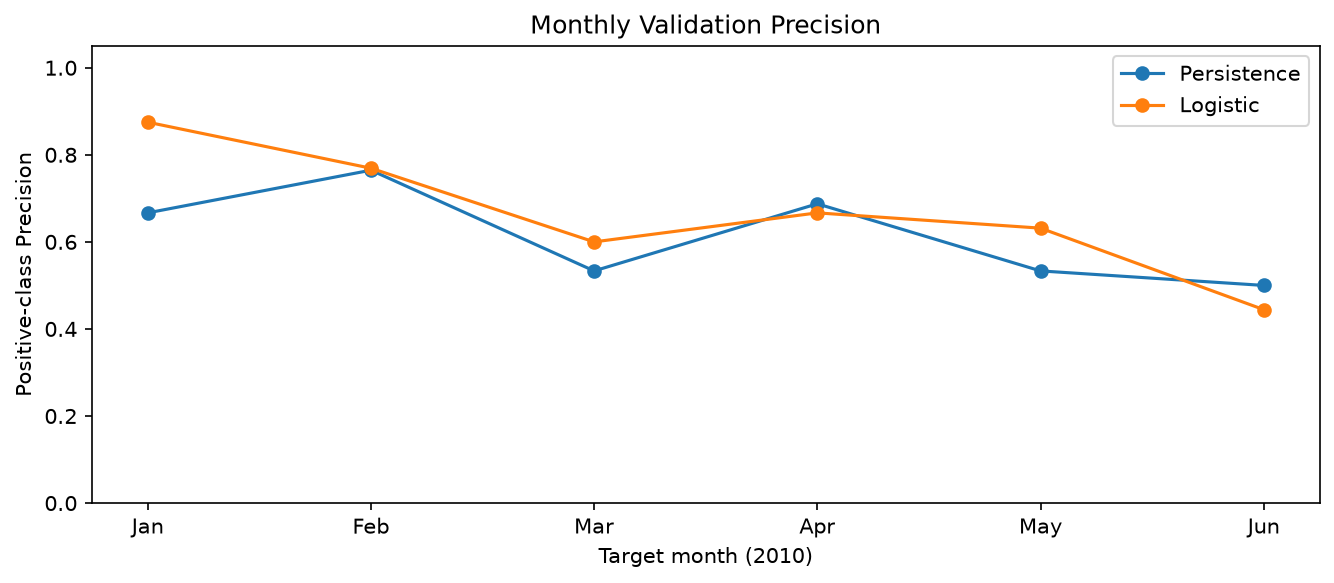

In [71]:
persistence_month_plot = monthly_scores[monthly_scores["Model"] == "Persistence"]
logistic_month_plot = monthly_scores[monthly_scores["Model"] == "Logistic"]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(persistence_month_plot["target_month"], persistence_month_plot["Precision"], marker="o", label="Persistence")
ax.plot(logistic_month_plot["target_month"], logistic_month_plot["Precision"], marker="o", label="Logistic")
ax.set_xticks(range(1, 7), validation_month_labels)
ax.set_ylim(0, 1.05)
ax.set_xlabel("Target month (2010)")
ax.set_ylabel("Positive-class Precision")
ax.set_title("Monthly Validation Precision")
ax.legend()
fig.tight_layout()

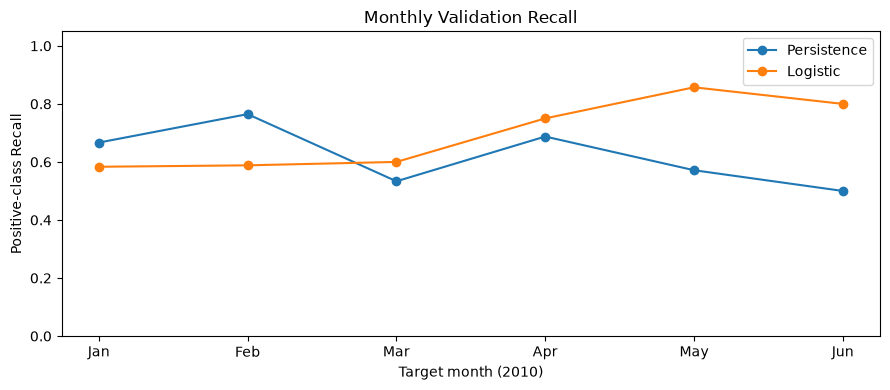

In [72]:
persistence_month_plot = monthly_scores[monthly_scores["Model"] == "Persistence"]
logistic_month_plot = monthly_scores[monthly_scores["Model"] == "Logistic"]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(persistence_month_plot["target_month"], persistence_month_plot["Recall"], marker="o", label="Persistence")
ax.plot(logistic_month_plot["target_month"], logistic_month_plot["Recall"], marker="o", label="Logistic")
ax.set_xticks(range(1, 7), validation_month_labels)
ax.set_ylim(0, 1.05)
ax.set_xlabel("Target month (2010)")
ax.set_ylabel("Positive-class Recall")
ax.set_title("Monthly Validation Recall")
ax.legend()
fig.tight_layout()

### What the monthly results show

Logistic regression finds a larger share of positive days in March through June, but a smaller share in January and February. Precision is higher in some months and lower in others. In June it finds 8 of 10 positive days and gives 10 false alarms. Always-zero has higher accuracy that month but finds none of the positive days.

Looking month by month shows mistakes that the overall score hides. I only have six validation months, so this is not enough to say that the seasons caused the differences. Next I check whether I need all five weather inputs.

## 19. Do I need the other weather inputs?

I compare using only today's tp with using tp, temperature, pressure, u, and v. Both logistic regression models use the same rows, dates, and 0.5 cutoff. The scaler learns from training data only.

I reuse the predictions from the five-input model above.

### Round 1: Jan-Feb 2010

In [73]:
tp_scaler_1 = StandardScaler()
X_tp_train_1 = tp_scaler_1.fit_transform(train_signal_1[["today_tp"]])
X_tp_val_1 = tp_scaler_1.transform(val_signal_1[["today_tp"]])

tp_model_1 = LogisticRegression(max_iter=1000)
tp_model_1.fit(X_tp_train_1, train_signal_1["tomorrow_signal"])
val_signal_1["tp_only"] = tp_model_1.predict(X_tp_val_1)

print("Precipitation-only recall:", recall_score(val_signal_1["tomorrow_signal"], val_signal_1["tp_only"], zero_division=0))
print("All-weather recall:", recall_score(val_signal_1["tomorrow_signal"], val_signal_1["logistic"], zero_division=0))

Precipitation-only recall: 0.4482758620689655
All-weather recall: 0.5862068965517241


### Round 2: Mar-Apr 2010

In [74]:
tp_scaler_2 = StandardScaler()
X_tp_train_2 = tp_scaler_2.fit_transform(train_signal_2[["today_tp"]])
X_tp_val_2 = tp_scaler_2.transform(val_signal_2[["today_tp"]])

tp_model_2 = LogisticRegression(max_iter=1000)
tp_model_2.fit(X_tp_train_2, train_signal_2["tomorrow_signal"])
val_signal_2["tp_only"] = tp_model_2.predict(X_tp_val_2)

print("Precipitation-only recall:", recall_score(val_signal_2["tomorrow_signal"], val_signal_2["tp_only"], zero_division=0))
print("All-weather recall:", recall_score(val_signal_2["tomorrow_signal"], val_signal_2["logistic"], zero_division=0))

Precipitation-only recall: 0.1935483870967742
All-weather recall: 0.6774193548387096


### Round 3: May-Jun 2010

In [75]:
tp_scaler_3 = StandardScaler()
X_tp_train_3 = tp_scaler_3.fit_transform(train_signal_3[["today_tp"]])
X_tp_val_3 = tp_scaler_3.transform(val_signal_3[["today_tp"]])

tp_model_3 = LogisticRegression(max_iter=1000)
tp_model_3.fit(X_tp_train_3, train_signal_3["tomorrow_signal"])
val_signal_3["tp_only"] = tp_model_3.predict(X_tp_val_3)

print("Precipitation-only recall:", recall_score(val_signal_3["tomorrow_signal"], val_signal_3["tp_only"], zero_division=0))
print("All-weather recall:", recall_score(val_signal_3["tomorrow_signal"], val_signal_3["logistic"], zero_division=0))

Precipitation-only recall: 0.0
All-weather recall: 0.8333333333333334


### Compare all 181 validation days

I join the predictions from the three rounds and compare the same scores.

In [76]:
input_comparison_days = pd.concat([val_signal_1, val_signal_2, val_signal_3])
y_input_comparison = input_comparison_days["tomorrow_signal"]

tp_only_scores = {
    "Model": "Precipitation only",
    "Accuracy": accuracy_score(y_input_comparison, input_comparison_days["tp_only"]),
    "Precision": precision_score(y_input_comparison, input_comparison_days["tp_only"], zero_division=0),
    "Recall": recall_score(y_input_comparison, input_comparison_days["tp_only"], zero_division=0),
}
all_weather_scores = logistic_scores_all.copy()
all_weather_scores["Model"] = "All weather inputs"
input_comparison = pd.DataFrame([tp_only_scores, all_weather_scores])
input_comparison.round(4)

,Model,Accuracy,Precision,Recall
0,Precipitation only,0.6077,0.7600,0.2262
1,All weather inputs,0.6740,0.6374,0.6905


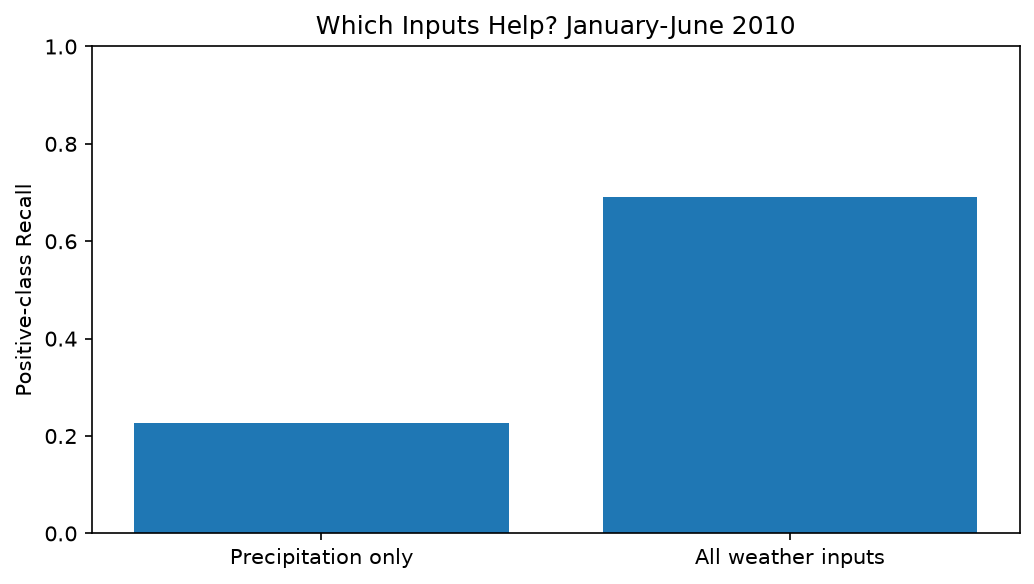

In [77]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(input_comparison["Model"], input_comparison["Recall"])
ax.set_ylabel("Positive-class Recall")
ax.set_ylim(0, 1)
ax.set_title("Which Inputs Help? January-June 2010")
fig.tight_layout()

## 20. What I found for positive-or-zero prediction

Using all five inputs finds more positive days overall than using tp alone: recall rises from 0.2262 to 0.6905. But precision falls from 0.7600 to 0.6374, so there is a tradeoff. I keep the five inputs because I want to miss fewer positive days.

The improvement over persistence is smaller: recall is 0.6905 compared with 0.6310, and precision is 0.6374 compared with 0.6235. This is still a prediction of whether the file's value is above zero.

Notebook 06 checks this model on July-December. Next I try predicting how large tomorrow's value will be.

## 21. Try predicting the precipitation value

So far, I have predicted positive or zero. Now I try predicting the number itself.

I use today's five weather variables and their 3-day and 7-day averages. I match the dates from the files already loaded and use January 2009-June 2010.

I change tp from meters to mm to make the values easier to read. I am still predicting the average saved in the file, not a daily rainfall total.

In [78]:
from pathlib import Path
import numpy as np
import matplotlib.dates as mdates
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import precision_score, recall_score, accuracy_score

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

In [79]:
temp_grid = (ds_temp["t2m"] - 273.15).sel(valid_time=slice("2009-01-01", "2010-06-30"))
temp_point = temp_grid.sel(latitude=33.75, longitude=-117.75, method="nearest")
temp_series = temp_point.compute(scheduler="single-threaded").to_series().astype(float)

In [80]:
pressure_grid = (ds_pressure["msl"] / 100).sel(valid_time=slice("2009-01-01", "2010-06-30"))
pressure_point = pressure_grid.sel(latitude=33.75, longitude=-117.75, method="nearest")
pressure_series = pressure_point.compute(scheduler="single-threaded").to_series().astype(float)

In [81]:
u_grid = (ds_u["u10"]).sel(valid_time=slice("2009-01-01", "2010-06-30"))
u_point = u_grid.sel(latitude=33.75, longitude=-117.75, method="nearest")
u_series = u_point.compute(scheduler="single-threaded").to_series().astype(float)

In [82]:
v_grid = (ds_v["v10"]).sel(valid_time=slice("2009-01-01", "2010-06-30"))
v_point = v_grid.sel(latitude=33.75, longitude=-117.75, method="nearest")
v_series = v_point.compute(scheduler="single-threaded").to_series().astype(float)

In [83]:
tp_grid = (ds_precip["tp"] * 1000).sel(valid_time=slice("2009-01-01", "2010-06-30"))
tp_point = tp_grid.sel(latitude=33.75, longitude=-117.75, method="nearest")
tp_series = tp_point.compute(scheduler="single-threaded").to_series().astype(float)

In [84]:
weather = pd.DataFrame({"temp": temp_series, "pressure": pressure_series,
                        "u": u_series, "v": v_series, "tp": tp_series})
assert weather.index.is_unique and weather.index.is_monotonic_increasing
assert weather.index.equals(pd.date_range("2009-01-01", "2010-06-30", name="valid_time"))
assert weather.notna().all().all()
print("Selected point:", float(temp_point.latitude), float(temp_point.longitude))
print(weather.isna().sum())
weather.head()

Selected point: 33.75 -117.75
temp        0
pressure    0
u           0
v           0
tp          0
dtype: int64


,temp,pressure,u,v,tp
valid_time,,,,,
2009-01-01,10.976807,1017.050415,-0.581250,0.012833,0.000040
2009-01-02,10.043762,1014.690857,-0.532312,0.843110,0.000139
2009-01-03,10.752289,1013.045654,-0.766132,1.317292,0.015299
2009-01-04,10.557648,1014.790527,-0.897218,-0.563737,0.015477
2009-01-05,7.683075,1020.252808,-0.796495,-0.120888,0.000000


In [85]:
daily_features = ["temp", "pressure", "u", "v", "tp"]
for name in daily_features:
    weather[name + "_3day"] = weather[name].rolling(3).mean()
    weather[name + "_7day"] = weather[name].rolling(7).mean()

all_features = list(weather.columns)
temp_features = ["temp", "temp_3day", "temp_7day"]
tp_features = ["tp", "tp_3day", "tp_7day"]
weather.head(8)

,temp,pressure,u,v,tp,temp_3day,temp_7day,pressure_3day,pressure_7day,u_3day,u_7day,v_3day,v_7day,tp_3day,tp_7day
valid_time,,,,,,,,,,,,,,,
2009-01-01,10.976807,1017.050415,-0.581250,0.012833,0.000040,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2009-01-02,10.043762,1014.690857,-0.532312,0.843110,0.000139,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2009-01-03,10.752289,1013.045654,-0.766132,1.317292,0.015299,10.590953,NaN,1014.928975,NaN,-0.626565,NaN,0.724412,NaN,0.005159,NaN
2009-01-04,10.557648,1014.790527,-0.897218,-0.563737,0.015477,10.451233,NaN,1014.175680,NaN,-0.731887,NaN,0.532222,NaN,0.010305,NaN
2009-01-05,7.683075,1020.252808,-0.796495,-0.120888,0.000000,9.664337,NaN,1016.029663,NaN,-0.819948,NaN,0.210889,NaN,0.010259,NaN
2009-01-06,9.233704,1019.683228,-0.606314,0.634251,0.000000,9.158142,NaN,1018.242188,NaN,-0.766676,NaN,-0.016791,NaN,0.005159,NaN
2009-01-07,10.581696,1021.168518,-0.424782,0.109842,0.000000,9.166158,9.975568,1020.368184,1017.240287,-0.609197,-0.657786,0.207735,0.318958,0.000000,0.004422
2009-01-08,11.220703,1017.560364,-0.259017,0.284220,0.000079,10.345367,10.010411,1019.470703,1017.313137,-0.430038,-0.611753,0.342771,0.357727,0.000026,0.004428


## 22. Try nearby temperature and precipitation

I take the average temperature of the nine points in a 3 by 3 square around Irvine. I do the same for precipitation and add both averages as inputs.

These are averages across nearby places on today's map. Some points may be over the ocean; I have not checked that yet.

In [86]:
temp_nearby = temp_grid.sel(latitude=slice(34.0, 33.5), longitude=slice(-118.0, -117.5))
tp_nearby = tp_grid.sel(latitude=slice(34.0, 33.5), longitude=slice(-118.0, -117.5))
assert temp_nearby.sizes["latitude"] == 3 and temp_nearby.sizes["longitude"] == 3
weather["nearby_temp"] = temp_nearby.mean(["latitude", "longitude"]).compute(scheduler="single-threaded").to_series()
weather["nearby_tp"] = tp_nearby.mean(["latitude", "longitude"]).compute(scheduler="single-threaded").to_series()
print("Nearby latitudes:", temp_nearby.latitude.values)
print("Nearby longitudes:", temp_nearby.longitude.values)
spatial_features = all_features + ["nearby_temp", "nearby_tp"]

Nearby latitudes: [34.   33.75 33.5 ]
Nearby longitudes: [-118.   -117.75 -117.5 ]


### Compare the same days

I use the same validation dates for every model. I also check that the answers used for training would already be known when I start predicting. This matters when I try two and three days ahead.

The functions below collect the predictions and calculate scores. I use all the daily errors from the three rounds together to get the overall MAE and RMSE.

In [87]:
periods = [("2010-01-01", "2010-03-01"),
           ("2010-03-01", "2010-05-01"),
           ("2010-05-01", "2010-07-01")]

def regression_scores(predictions):
    rows = []
    for name, part in predictions.groupby("model", sort=False):
        errors = part["predicted"] - part["actual"]
        rows.append({"Model": name, "Days": len(part),
                     "MAE": errors.abs().mean(),
                     "RMSE": np.sqrt((errors ** 2).mean())})
    return pd.DataFrame(rows)

def save_predictions(parts, name, valid, prediction):
    parts.append(pd.DataFrame({"model": name, "date": valid["target_date"].values,
                               "actual": valid["target"].values,
                               "predicted": np.asarray(prediction)}))

## 23. Compare models for the precipitation value

I try recent averages, more weather variables, nearby points, predicting the change, and a small neural network. I compare them with persistence and always predicting zero.

Linear regression can give a negative prediction. I change negative predictions to zero for every trained model, using the same rule before comparing their scores.

I try the same small network as for temperature: one hidden layer with 8 ReLU units, random seed 42, and alpha 0.1. I use training data to scale the inputs and answers. I keep these settings the same in all three rounds.

In [88]:
tp_model = weather.copy()
tp_model["target"] = weather["tp"].shift(-1)
tp_model["target_date"] = weather.index + pd.Timedelta(days=1)
tp_model = tp_model.dropna().copy()
tp_parts = []
tp_checks = []

In [89]:
# Refit the models on earlier dates in each round.
for start, end in periods:
    first_forecast_day = pd.Timestamp(start) - pd.Timedelta(days=1)
    train = tp_model[tp_model["target_date"] <= first_forecast_day].copy()
    valid = tp_model[(tp_model["target_date"] >= start) &
                           (tp_model["target_date"] < end)].copy()
    assert train["target_date"].max() <= valid.index.min()
    save_predictions(tp_parts, "Persistence", valid, valid["tp"])
    save_predictions(tp_parts, "Always zero", valid, np.zeros(len(valid)))

    for name, inputs in [("Own rolling averages", tp_features),
                         ("All weather and averages", all_features),
                         ("Add nearby means", spatial_features)]:
        model = LinearRegression()
        model.fit(train[inputs], train["target"])
        prediction = model.predict(valid[inputs])
        prediction = np.maximum(prediction, 0)
        save_predictions(tp_parts, name, valid, prediction)

    absolute_model = LinearRegression().fit(train[all_features], train["target"])
    change_model = LinearRegression()
    change_model.fit(train[all_features], train["target"] - train["tp"])
    change_prediction = change_model.predict(valid[all_features]) + valid["tp"].values
    largest_difference = np.abs(change_prediction - absolute_model.predict(valid[all_features])).max()
    tp_checks.append({"Period": start[:7], "Train": len(train), "Validation": len(valid),
                           "Absolute/change maximum difference": largest_difference})
    change_prediction = np.maximum(change_prediction, 0)
    save_predictions(tp_parts, "Predict the change", valid, change_prediction)

    x_scaler = StandardScaler().fit(train[all_features])
    y_scaler = StandardScaler().fit(train[["target"]])
    network = MLPRegressor(hidden_layer_sizes=(8,), activation="relu", solver="lbfgs",
                           alpha=0.1, max_iter=10000, max_fun=150000, random_state=42)
    network.fit(x_scaler.transform(train[all_features]),
                y_scaler.transform(train[["target"]]).ravel())
    print("Network round", start[:7], "iterations:", network.n_iter_, "training loss:", network.loss_)
    scaled_prediction = network.predict(x_scaler.transform(valid[all_features]))
    nn_prediction = y_scaler.inverse_transform(scaled_prediction.reshape(-1, 1)).ravel()
    nn_prediction = np.maximum(nn_prediction, 0)
    save_predictions(tp_parts, "Small neural network", valid, nn_prediction)

tp_predictions = pd.concat(tp_parts, ignore_index=True)
tp_scores = regression_scores(tp_predictions)
print(pd.DataFrame(tp_checks).to_string(index=False))
tp_scores.round(5)

Network round 2010-01 iterations: 407 training loss: 0.08251232673183352


Network round 2010-03 iterations: 1887 training loss: 0.1070695894583493


Network round 2010-05 iterations: 3306 training loss: 0.11108946605063015
 Period  Train  Validation  Absolute/change maximum difference
2010-01    358          59                        4.274359e-15
2010-03    417          61                        6.217249e-15
2010-05    478          61                        6.217249e-15


,Model,Days,MAE,RMSE
0,Persistence,181,0.09380,0.32128
1,Always zero,181,0.07415,0.29232
2,Own rolling averages,181,0.09665,0.26711
3,All weather and averages,181,0.10409,0.26082
4,Add nearby means,181,0.10046,0.25775
5,Predict the change,181,0.10409,0.26082
6,Small neural network,181,0.11607,0.29730


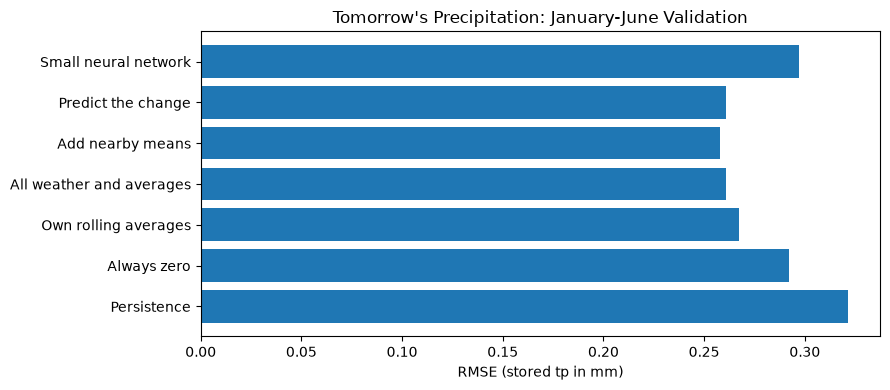

In [90]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(tp_scores["Model"], tp_scores["RMSE"])
ax.set_xlabel("RMSE (stored tp in mm)")
ax.set_title("Tomorrow's Precipitation: January-June Validation")
fig.tight_layout()

### What I notice about precipitation

The model with nearby points lowers RMSE from 0.3213 for persistence to 0.2578 mm. But its MAE is 0.1005, compared with 0.0938 for persistence and 0.0741 for always zero.

There are many zero or tiny values, which helps the always-zero model get a low MAE. RMSE gives bigger mistakes more weight. The best model here depends on which score I look at.

The small network does worse than the linear models on both scores. One training run reached the original limit of 2,000 steps. I allowed up to 10,000 steps for both temperature and precipitation, keeping the same inputs and network settings. All six runs then finished before reaching the limit, with no warning about needing more steps. I made this change to let training finish, not to pick a model with a better validation score.

## 24. Predict precipitation two and three days ahead

I train one model for tomorrow, another for two days later, and another for three days later. Each uses today's weather and the same recent averages to predict its day directly. For persistence, I use today's precipitation value for all three predictions.

I check the training dates too. For example, if I predict January 1 at the end of December 29, I can only use training answers known by December 29. The real precipitation values for December 30 and 31 are not available yet.

I compare the models on the same 181 days from January to June 2010.

In [91]:
future_parts = []
future_counts = []
for target in ["tp"]:
    for horizon in [1, 2, 3]:
        data = weather.copy()
        data["target"] = weather[target].shift(-horizon)
        data["target_date"] = weather.index + pd.Timedelta(days=horizon)
        data = data.dropna().copy()
        for start, end in periods:
            first_forecast_day = pd.Timestamp(start) - pd.Timedelta(days=horizon)
            train = data[data["target_date"] <= first_forecast_day]
            valid = data[(data["target_date"] >= start) & (data["target_date"] < end)]
            assert train["target_date"].max() <= valid.index.min()
            model = LinearRegression().fit(train[all_features], train["target"])
            prediction = model.predict(valid[all_features])
            if target == "tp":
                prediction = np.maximum(prediction, 0)
            parts = []
            save_predictions(parts, "Persistence", valid, valid[target])
            save_predictions(parts, "Linear regression", valid, prediction)
            part = pd.concat(parts, ignore_index=True)
            part["Target"] = target
            part["Horizon"] = horizon
            future_parts.append(part)
            future_counts.append({"Target": target, "Horizon": horizon, "Round": start[:7],
                                  "Train": len(train), "Validation": len(valid),
                                  "Last training target": train["target_date"].max(),
                                  "First forecast date": valid.index.min()})
future_predictions = pd.concat(future_parts, ignore_index=True)
future_rows = []
for (target, horizon), part in future_predictions.groupby(["Target", "Horizon"]):
    scores = regression_scores(part)
    scores["Target"] = target
    scores["Days ahead"] = horizon
    future_rows.append(scores)
future_scores = pd.concat(future_rows, ignore_index=True)
future_scores[["Target", "Days ahead", "Model", "Days", "MAE", "RMSE"]].round(5)

,Target,Days ahead,Model,Days,MAE,RMSE
0,tp,1,Persistence,181,0.09380,0.32128
1,tp,1,Linear regression,181,0.10409,0.26082
2,tp,2,Persistence,181,0.11784,0.37067
3,tp,2,Linear regression,181,0.11571,0.28161
4,tp,3,Persistence,181,0.11459,0.35341
5,tp,3,Linear regression,181,0.11328,0.28935


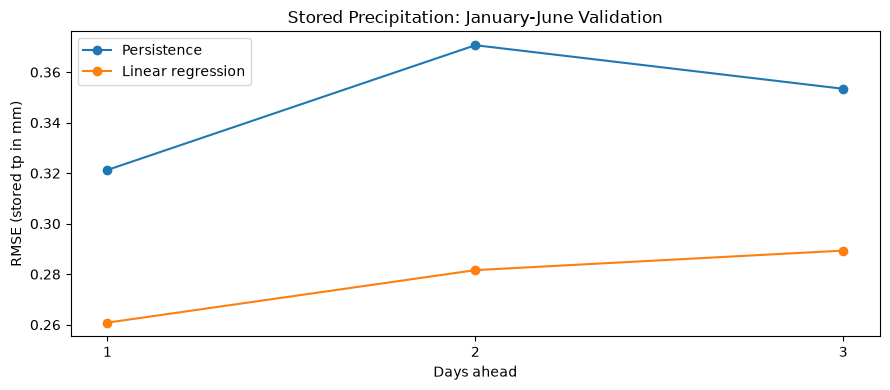

In [92]:
fig, ax = plt.subplots(figsize=(9, 4))
for name in ["Persistence", "Linear regression"]:
    part = future_scores[future_scores["Model"] == name]
    ax.plot(part["Days ahead"], part["RMSE"], marker="o", label=name)
ax.set_xticks([1, 2, 3])
ax.set_xlabel("Days ahead")
ax.set_ylabel("RMSE (stored tp in mm)")
ax.set_title("Stored Precipitation: January-June Validation")
ax.legend()
fig.tight_layout()

### What happened when I predicted further ahead?

Linear regression has an RMSE of 0.2608 mm for tomorrow, 0.2816 for two days ahead, and 0.2893 for three days ahead. The errors grow, but RMSE stays below persistence at all three distances. Persistence does have a lower MAE for tomorrow.

These scores are for the precipitation values saved in the files.

## 25. What I found

Logistic regression helps a little with predicting positive or zero: its January-June precision and recall are slightly higher than persistence. For predicting the number itself, nearby points give the lowest RMSE, while always zero gives the lowest MAE. Looking at just one score would miss that difference.

Predicting the change gives the same linear predictions as predicting the value directly. The small neural network does worse. These trials were still useful because they showed that adding a method does not always improve the result.

I still need to confirm how the daily precipitation values were calculated. Notebook 06 checks the positive-or-zero model on July-December, but it does not test the models for the numerical values here. I would need unused dates for a new test of those models.

In [93]:
OUTPUT_DIR = PROJECT_DIR.parent / "Project1_WeatherPrediction_materials" / "results" / "model_comparisons"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
tp_scores.to_csv(OUTPUT_DIR / "precipitation_values.csv", index=False)
tp_predictions.to_csv(OUTPUT_DIR / "precipitation_predictions.csv", index=False)
future_scores.to_csv(OUTPUT_DIR / "precipitation_horizons.csv", index=False)
future_predictions.to_csv(OUTPUT_DIR / "precipitation_horizon_predictions.csv", index=False)
pd.DataFrame(future_counts).to_csv(OUTPUT_DIR / "precipitation_forecast_date_checks.csv", index=False)

round_tables = []
for start, end in periods:
    part = tp_predictions[(tp_predictions["date"] >= start) & (tp_predictions["date"] < end)]
    scores = regression_scores(part)
    scores["Period"] = start[:7]
    round_tables.append(scores)
pd.concat(round_tables, ignore_index=True).to_csv(OUTPUT_DIR / "precipitation_by_round.csv", index=False)
print("Saved the comparison tables.")

Saved the comparison tables.
